# Fixing a small AI model's "overthinking" by editing its brain directly

**A visual, plain-language tour of the results.** Every number here is computed live from the files in `data/`.
Hover over any chart for an explanation of what each point means in practice. Dotted-underlined terms show a
definition when you hover over them.

**The story in one paragraph.** Small AI models that "think before answering" often get stuck repeating
themselves: *"Wait, let me check... Yes... Wait, let me check..."*. They run out of space before they ever write an
answer. The usual fix is **fine-tuning**: show the model thousands of examples and retrain it. We tried a different
approach. We gave an AI agent (Claude) access to the model's internal numbers, its
<abbr title="The billions of numbers that make up a neural network; changing them changes how it behaves">weights</abbr>,
and asked it to perform surgery: make the smallest change that stops the looping. The agent made four small,
targeted changes. Three of them each touch a single "neuron" out of the model's ~86,000, and the fourth is one gentle
adjustment to the last layer. With them, the model went from solving **15%** to **67%** of a set of school math
problems. That beats every alternative we tried, including fine-tuning, which took 13 times more computer
time and reached 29%.

> **The model:** Qwen3.5-0.8B, a free, open AI model with 0.8 billion weights, small enough for a gaming graphics
> card. **The computer:** a single consumer GPU (GTX 1660 SUPER, 6 GB). **The test:** grade-school math word
> problems (GSM8K) and harder competition math (MATH-500).

### Glossary (hover the terms anywhere in the notebook)

| term | what it means in practice |
|---|---|
| <abbr title="Fraction of problems where the final answer is exactly right">**accuracy**</abbr> | out of 100 problems, how many it gets right |
| <abbr title="The model's private scratchpad before it answers; it ends with a special 'I'm done thinking' marker">**thinking**</abbr> | the model reasons in a scratchpad first, then writes the answer |
| <abbr title="A token is a piece of a word; 1,000 tokens is roughly 750 English words">**token**</abbr> | about ¾ of a word. The space limit is 12,288 tokens, roughly 9,000 words or 18 pages |
| <abbr title="The model used its whole token allowance without closing its thinking, so it never wrote an answer">**ran out of space**</abbr> | the model never finished thinking, almost always because it was looping |
| <abbr title="The edited model got this problem right AND the other one got it wrong (a 'rescue'); or the reverse (a 'loss')">**rescue / loss**</abbr> | a head-to-head on the *same* problem with the *same* random seed: who got it right that the other missed |
| <abbr title="The range in which the true value probably lies, given how few problems we tested; ±1 standard error">**error bar**</abbr> | the wiggle room from testing on only 32–148 problems; bars that overlap a lot are not clearly different |
| <abbr title="A problem set used to choose between options; we looked at it many times">**dev set**</abbr> | the 48 practice problems we used to make decisions |
| <abbr title="A problem set kept sealed; each method was run on it once, after all choices were made">**locked test**</abbr> | 32 sealed problems, opened once per method to keep us honest |
| <abbr title="One hour of the graphics card working at full load">**GPU-hour**</abbr> | one hour of the graphics card's time, roughly 0.2 kWh of electricity on this machine |

In [1]:
import base64, json, math, os, shutil
from datetime import datetime
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
load = lambda name: json.load(open(DATA / name))

# Static PNG copies (for viewers without plotly, e.g. GitHub) need kaleido + a Chrome/Chromium.
# A snap-confined Chromium can only read non-hidden folders in $HOME, so point kaleido's temp files there.
if not os.environ.get("BROWSER_PATH") and shutil.which("chromium-browser") and Path("/snap/bin/chromium").exists():
    os.environ["BROWSER_PATH"] = shutil.which("chromium-browser")
    tmp = Path.home() / "snaptmp"; tmp.mkdir(exist_ok=True)
    import tempfile; tempfile.tempdir = str(tmp)

# --- palette (validated: adjacent CVD ΔE ≥ 9, normal-vision ΔE ≥ 27) and text tokens ---
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
NAVY, RED, GRAY, LIGHTGRAY = "#184f95", "#e34948", "#8a8985", "#c3c2b7"
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e8e7e3"

def style(fig, height=420, title=None, subtitle=None):
    t = f"<b>{title}</b>" + (f"<br><span style='font-size:13px;color:{INK2}'>{subtitle}</span>" if subtitle else "")
    fig.update_layout(
        title=dict(text=t, x=0, xref="container", xanchor="left", pad=dict(l=32, t=8), font=dict(size=17, color=INK)) if title else None,
        height=height, paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
        font=dict(family="Inter, Helvetica, Arial, sans-serif", size=13, color=INK2),
        margin=dict(l=40, r=40, t=120 if title else 30, b=48, pad=4),
        hoverlabel=dict(bgcolor="white", bordercolor=LIGHTGRAY, font=dict(size=13, color=INK), align="left"),
        legend=dict(orientation="h", y=-0.18, x=0, xref="paper", font=dict(color=INK2)),
        bargap=0.25,
    )
    fig.update_xaxes(gridcolor=GRID, zerolinecolor=LIGHTGRAY, linecolor=LIGHTGRAY, tickfont=dict(color=INK2))
    fig.update_yaxes(gridcolor=GRID, zerolinecolor=LIGHTGRAY, linecolor=LIGHTGRAY, tickfont=dict(color=INK2))
    return fig

def show(fig, width=960):
    """Interactive plotly figure (hover tooltips) + a static PNG copy for viewers that can't run plotly."""
    bundle = {"application/vnd.plotly.v1+json": {**json.loads(fig.to_json()),
                                                 "config": {"displaylogo": False, "responsive": True}}}
    try:
        png = fig.to_image(format="png", width=width, height=fig.layout.height or 420, scale=1.5)
        bundle["image/png"] = base64.b64encode(png).decode()
    except Exception:
        pass
    bundle["text/plain"] = "[interactive chart: open in Jupyter/VS Code for tooltips]"
    display(bundle, raw=True)

def se(p, n):
    return math.sqrt(p * (1 - p) / n) if n else 0

print("data folder:", DATA)

data folder: /mnt/dados/dev/agentic-weight-editing/data


In [2]:
# Every method ("arm") we compare, with a plain-language description shown in tooltips.
ARMS = {
    "base": ("Original model", GRAY,
             "Qwen3.5-0.8B exactly as released. No changes."),
    "astra": ("Astra edit (prior work)", ORANGE,
              "The weight edit published in 'Sparks of Weight-Space Programming' (MIT, 2026), found by GPT-6 'Astra'<br>in 20 hours. It weakens one internal 'repetition' signal."),
    "lbx_w10_t1": ("Word ban", AQUA,
                   "No weight change. While the model writes, we make the word 'Wait' almost forbidden<br>and nudge it to stop thinking (a 'logit bias'). Best of 3 settings we tuned."),
    "bf4096": ("Thinking time limit", AQUA,
               "No weight change. After 4,096 tokens (~3,000 words) of thinking we cut it off<br>and force the model to answer ('budget forcing'). Best of 2 settings we tuned."),
    "m2a_naive": ("Automated search (no agent)", LIGHTGRAY,
                  "A script that tried edits from the same toolbox as the agent, with the same budget<br>and the same feedback, but without an AI reasoning about what to try."),
    "ft_sft_ep2": ("Fine-tuning (LoRA)", VIOLET,
                   "Classic training: 175 examples of the model's own loop-free reasoning, 3 rounds,<br>17 GPU-hours. A standard, cheap fine-tuning recipe."),
    "m2a_a1_062959_102": ("Agent edit (ours)", BLUE,
                          "Four tiny changes found by a Claude agent in ~2 hours: quiet the impulse to say 'Wait'<br>(3 internal 'neurons') and strengthen the 'I'm done thinking' signal."),
    "m2a_a2": ("Agent edit, 2nd agent", BLUE,
               "A second, independent agent with the same instructions. It found the same 'Wait' neurons on its own."),
    "m2a_a1_062959_102+bf4096": ("Agent edit + time limit", NAVY,
                                 "The agent's edit combined with the thinking time limit."),
}
label = lambda a: ARMS[a][0]
color = lambda a: ARMS[a][1]
desc = lambda a: ARMS[a][2]

# Per-problem results for every evaluation
gen = {t: load(f"gen_{t}.json")["arms"] for t in ["dev48", "t12k", "t200", "math48", "math100b"]}

def rows(tag, arm):
    if tag == "math148":  # MATH-500[0:148] = math48 (first 48) + math100b (next 100)
        return gen["math48"][arm]["rows"] + gen["math100b"][arm]["rows"]
    return gen[tag][arm]["rows"]

def has(tag, arm):
    return all(arm in gen[t] for t in (["math48", "math100b"] if tag == "math148" else [tag]))

def acc(tag, arm):
    r = rows(tag, arm); k = sum(x["correct"] for x in r); return k, len(r)

SETS = {"dev48": "Practice set (GSM8K, 48)", "t12k": "Locked test 1 (GSM8K, 32)", "t200": "Locked test 2 (GSM8K, 200)", "math148": "Harder math (MATH-500, 148)"}

## 1. The problem: the model talks itself in circles

Each bar counts how many answers were a given length. The dashed line is the space limit. An answer at the limit
means the model was still "thinking" when it ran out of room, so it **never wrote an answer**.

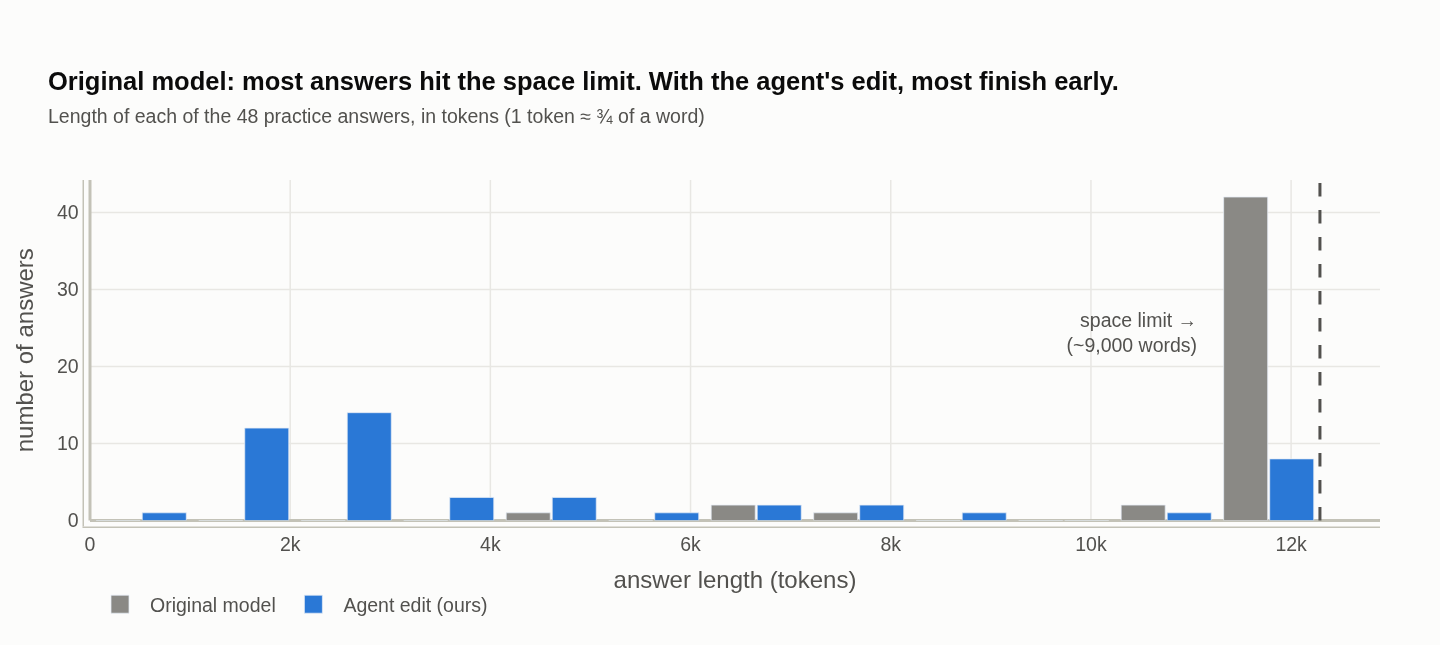


| | ran out of space | solved |
|---|---|---|
| **Original model** | **85%** of answers | 7 of 48 |
| **With the agent's edit** | **17%** of answers | 32 of 48 |


In [3]:
CAP = 12288
bins = list(range(0, CAP + 1024, 1024))
fig = go.Figure()
for arm in ["base", "m2a_a1_062959_102"]:
    r = rows("dev48", arm)
    df = pd.DataFrame({"tok": [x["n_tokens"] for x in r], "ok": [x["correct"] for x in r], "cut": [x["cut"] for x in r]})
    df["bin"] = pd.cut(df.tok.clip(upper=CAP - 1), bins, right=False, labels=bins[:-1]).astype(int)
    g = df.groupby("bin").agg(n=("ok", "size"), ok=("ok", "sum"), cut=("cut", "sum")).reindex(bins[:-1], fill_value=0)
    custom = [[b, b + 1024, int(b * 0.75), int((b + 1024) * 0.75), n, k, c] for b, n, k, c in zip(g.index, g.n, g.ok, g.cut)]
    fig.add_bar(x=[b + 512 for b in g.index], y=g.n, name=label(arm), marker_color=color(arm), width=440,
                offset=-450 if arm == "base" else 10, customdata=custom,
                hovertemplate=f"<b>{label(arm)}</b><br>%{{customdata[4]}} answers were %{{customdata[0]:,}}–%{{customdata[1]:,}} tokens long"
                              "<br>(about %{customdata[2]:,}–%{customdata[3]:,} words)<br>correct: %{customdata[5]} · ran out of space: %{customdata[6]}<extra></extra>")
fig.add_vline(x=CAP, line_dash="dash", line_color=INK2)
fig.add_annotation(x=CAP - 1200, y=0.55, yref="paper", text="space limit →<br>(~9,000 words)", showarrow=False, xanchor="right", align="right", font=dict(color=INK2))
style(fig, 430, "Original model: most answers hit the space limit. With the agent's edit, most finish early.",
      "Length of each of the 48 practice answers, in tokens (1 token ≈ ¾ of a word)")
fig.update_xaxes(title="answer length (tokens)", range=[0, CAP + 600])
fig.update_yaxes(title="number of answers")
show(fig)

cut = {a: gen["dev48"][a]["summary"]["cut"] for a in ["base", "m2a_a1_062959_102"]}
display(Markdown(f"""
| | ran out of space | solved |
|---|---|---|
| **Original model** | **{cut['base']:.0%}** of answers | {acc('dev48','base')[0]} of 48 |
| **With the agent's edit** | **{cut['m2a_a1_062959_102']:.0%}** of answers | {acc('dev48','m2a_a1_062959_102')[0]} of 48 |
"""))

> **In practice:** the original model often *knows how* to solve the problem, but it keeps second-guessing itself
> ("Wait, ...") until it runs out of room. Prompting it with "don't repeat yourself" doesn't help: we tried, and it
> did no better than a meaningless placebo prompt. The defect lives in the model's habits, not in its knowledge.

## 2. The headline: which fix works best?

Each panel is a different set of problems. Bars show the share solved, and the thin black lines are the
<abbr title="The range in which the true value probably lies, given how few problems we tested; ±1 standard error">error bars</abbr>.
Hover a bar to see what the method is and how many problems it solved.

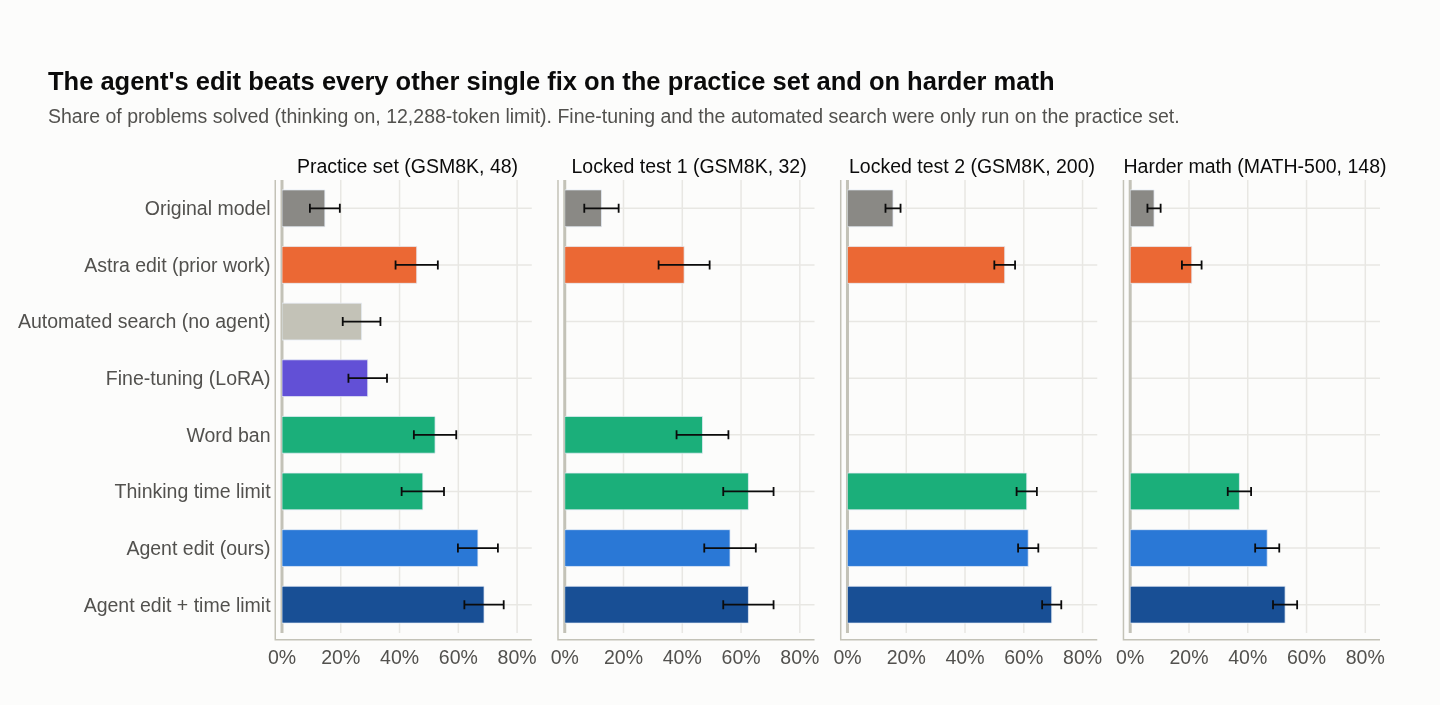

In [4]:
ORDER = ["base", "astra", "m2a_naive", "ft_sft_ep2", "lbx_w10_t1", "bf4096", "m2a_a1_062959_102", "m2a_a1_062959_102+bf4096"]
fig = make_subplots(rows=1, cols=len(SETS), shared_yaxes=True, horizontal_spacing=0.03, subplot_titles=list(SETS.values()))
for j, tag in enumerate(SETS, start=1):
    for arm in ORDER:
        if not has(tag, arm):
            continue
        k, n = acc(tag, arm); p = k / n
        fig.add_bar(y=[label(arm)], x=[p], orientation="h", marker_color=color(arm), showlegend=False,
                    error_x=dict(type="data", array=[se(p, n)], color=INK, thickness=1.2, width=3),
                    customdata=[[k, n, se(p, n) * 100, desc(arm)]],
                    hovertemplate=f"<b>{label(arm)}</b> on {SETS[tag]}<br>solved <b>%{{customdata[0]}} of %{{customdata[1]}}</b> (%{{x:.0%}}, ±%{{customdata[2]:.0f}} points)<br><br>%{{customdata[3]}}<extra></extra>",
                    row=1, col=j)
    fig.update_xaxes(range=[0, 0.85], tickformat=".0%", col=j)
style(fig, 470, "The agent's edit beats every other single fix on the practice set and on harder math",
      "Share of problems solved (thinking on, 12,288-token limit). Fine-tuning and the automated search were only run on the practice set.")
fig.update_yaxes(categoryorder="array", categoryarray=[label(a) for a in ORDER[::-1]])
fig.update_layout(barmode="overlay", bargap=0.35)
for a in fig.layout.annotations:
    a.font = dict(size=13, color=INK)
show(fig)

> **In practice:**
> - On the **practice set**, the agent's edit solves **2 of every 3 problems**. The original model solves 1 in 7,
>   fine-tuning about 1 in 3.
> - On the **locked test**, the edit and the time limit are statistically tied: 32 problems is too few to separate
>   them.
> - On **harder competition math**, which the agent never saw during its search, the edit clearly beats the time
>   limit. Long problems are exactly where a blunt cut-off hurts most.
> - The edit and the time limit **stack**: together they are the best on every set.

## 3. Head-to-head, problem by problem

Overall percentages can hide noise. Here every competitor is run on the **same problems with the same random
seed** as the agent's edit, and we count only the problems where exactly one of the two got it right.
- **Blue (right):** problems the agent's edit rescued, meaning the edit solved them and the competitor did not.
- **Red (left):** problems the competitor solved that the edit missed.

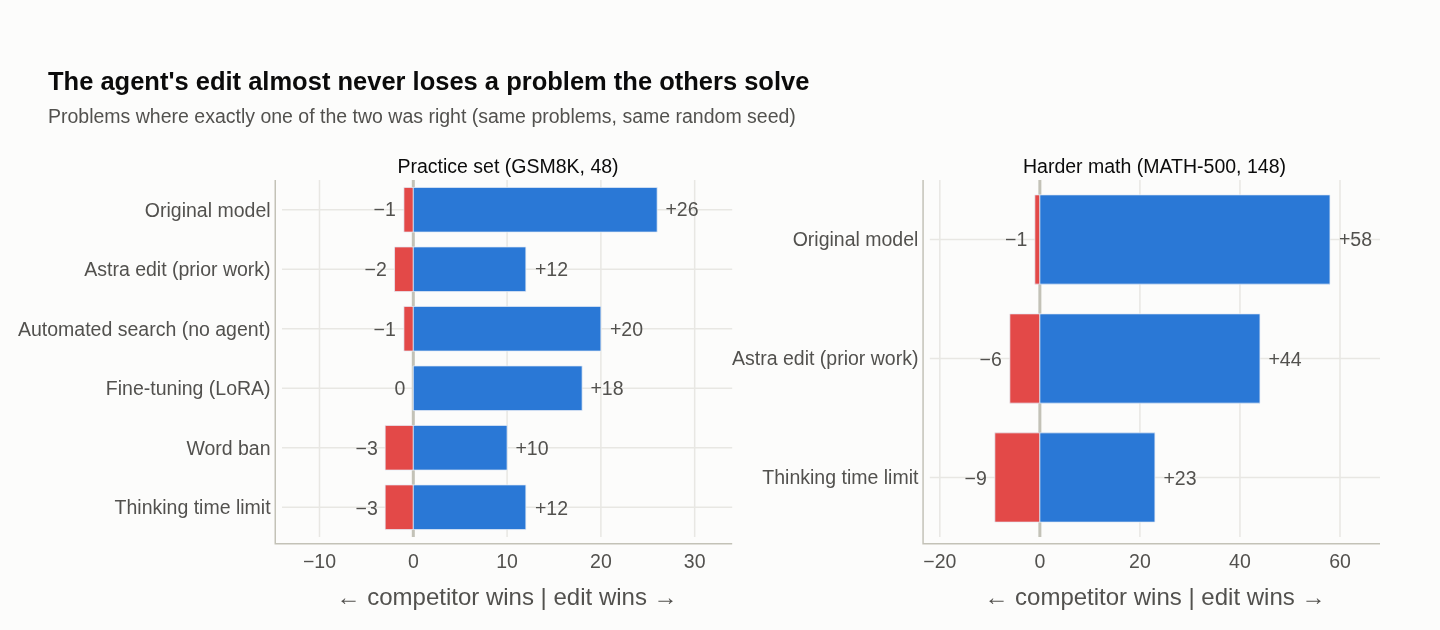

In [5]:
def paired(tag, a, b):
    ra, rb = rows(tag, a), rows(tag, b)
    win = sum(y["correct"] and not x["correct"] for x, y in zip(ra, rb))
    lose = sum(x["correct"] and not y["correct"] for x, y in zip(ra, rb))
    return win, lose, len(ra)

A1 = "m2a_a1_062959_102"
fig = make_subplots(rows=1, cols=2, shared_yaxes=False, horizontal_spacing=0.18,
                    subplot_titles=[SETS["dev48"], SETS["math148"]])
for j, tag in enumerate(["dev48", "math148"], start=1):
    comps = [a for a in ["base", "astra", "m2a_naive", "ft_sft_ep2", "lbx_w10_t1", "bf4096"] if has(tag, a)]
    for c in comps:
        w, l, n = paired(tag, c, A1)
        both = n - w - l
        fig.add_bar(y=[label(c)], x=[-l], orientation="h", marker_color=RED, showlegend=False,
                    customdata=[[label(c), l, w, both]],
                    hovertemplate="<b>vs %{customdata[0]}</b><br>%{customdata[1]} problems: only the competitor got it right<br>%{customdata[2]} problems: only the agent's edit got it right<br>%{customdata[3]} problems: same result for both<extra></extra>",
                    col=j, row=1)
        fig.add_bar(y=[label(c)], x=[w], orientation="h", marker_color=BLUE, showlegend=False,
                    customdata=[[label(c), l, w, both]], hovertemplate=fig.data[-1].hovertemplate, col=j, row=1)
        fig.add_annotation(x=w, y=label(c), text=f" +{w}", showarrow=False, xanchor="left", font=dict(color=INK2), col=j, row=1)
        fig.add_annotation(x=-l, y=label(c), text=f"−{l} " if l else "0 ", showarrow=False, xanchor="right", font=dict(color=INK2), col=j, row=1)
    fig.update_yaxes(categoryorder="array", categoryarray=[label(a) for a in comps[::-1]], col=j)
fig.update_layout(barmode="relative")
fig.update_xaxes(title="← competitor wins | edit wins →", zeroline=True, zerolinecolor=INK2)
fig.update_xaxes(range=[-14, 34], col=1); fig.update_xaxes(range=[-22, 68], col=2)
style(fig, 420, "The agent's edit almost never loses a problem the others solve",
      "Problems where exactly one of the two was right (same problems, same random seed)")
for a in fig.layout.annotations[:2]:
    a.font = dict(size=13, color=INK)
show(fig)

> **In practice:** against fine-tuning, the edit won on **18 problems and lost 0**. Against the published Astra edit,
> on the harder math set, it won 44 and lost 6. When two methods differ this one-sidedly on identical problems, the
> difference is not luck.

## 4. Why it works: stop the loops, and the answers follow

Every method and every edited model we ever tested on the practice set is one dot. Horizontally: how often it ran
out of space. Vertically: how often it was right.

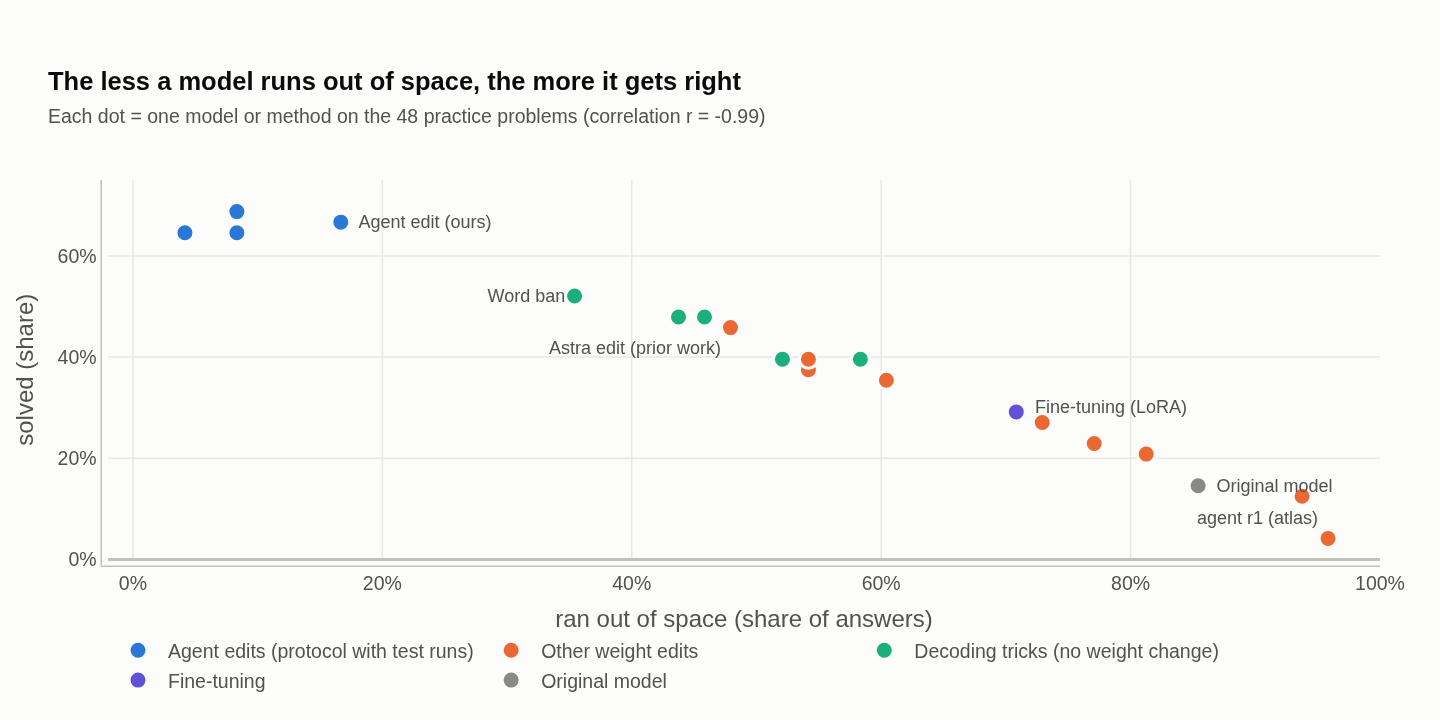

In [6]:
G = {"Agent edits (protocol with test runs)": BLUE, "Other weight edits": ORANGE, "Decoding tricks (no weight change)": AQUA,
     "Fine-tuning": VIOLET, "Original model": GRAY}
def group(a):
    if a == "base": return "Original model"
    if a.startswith("ft_"): return "Fine-tuning"
    if a.startswith(("lb", "bf")): return "Decoding tricks (no weight change)"
    if a in ("m2a_a1", A1, "m2a_a2", A1 + "+bf4096"): return "Agent edits (protocol with test runs)"
    return "Other weight edits"
NICE = {"m2a_r1": "agent r1 (atlas)", "m2a_a0": "agent a0", "m2a_r2": "agent r2 (atlas)", "m2a_r3": "agent r3 (atlas)",
        "m2a_a1": "agent a1 (1st pick)", "m2a_r1_192156_139": "agent r1 (3rd pick)", "m2a_dose_232243_057": "dose test 1",
        "m2a_dose_232709_125": "dose test 2", "lb_w10_t0": "word ban (setting 1)", "lb_w3_t1": "word ban (setting 3)",
        "bf8192": "time limit 8,192", "m2a_naive": "automated search"}
fig = go.Figure()
pts = []
for a, v in gen["dev48"].items():
    s = v["summary"]; n = len(v["rows"])
    pts.append((a, s["cut"], s["acc"], n, group(a)))
for gname, col in G.items():
    P = [p for p in pts if p[4] == gname]
    fig.add_scatter(x=[p[1] for p in P], y=[p[2] for p in P], mode="markers", name=gname,
                    marker=dict(size=12, color=col, line=dict(color=SURFACE, width=2)),
                    customdata=[[ARMS[p[0]][0] if p[0] in ARMS else NICE.get(p[0], p[0]), round(p[2] * p[3]), p[3], round(p[1] * p[3])] for p in P],
                    hovertemplate="<b>%{customdata[0]}</b><br>ran out of space on %{customdata[3]} of %{customdata[2]} (%{x:.0%})<br>solved %{customdata[1]} of %{customdata[2]} (%{y:.0%})<extra></extra>")
for a, xa, ys in [("base", "left", 0), (A1, "left", 0), ("astra", "right", -14), ("ft_sft_ep2", "left", 4), ("lbx_w10_t1", "right", 0), ("m2a_r1", "right", 14)]:
    p = next(p for p in pts if p[0] == a)
    fig.add_annotation(x=p[1], y=p[2], text=ARMS[a][0] if a in ARMS else NICE[a], showarrow=False,
                       xshift=10 if xa == "left" else -4, yshift=ys, xanchor=xa, font=dict(color=INK2, size=12))
import numpy as np
r = np.corrcoef([p[1] for p in pts], [p[2] for p in pts])[0, 1]
style(fig, 480, "The less a model runs out of space, the more it gets right",
      f"Each dot = one model or method on the 48 practice problems (correlation r = {r:.2f})")
fig.update_xaxes(title="ran out of space (share of answers)", tickformat=".0%", range=[-0.02, 1.0], zeroline=False)
fig.update_yaxes(title="solved (share)", tickformat=".0%", range=[0, 0.75])
show(fig)

> **In practice:** almost all of the improvement comes from letting the model **finish its thought**. Every method
> that cut the "ran out of space" rate also raised accuracy, roughly in proportion. The dot at the bottom right is
> agent r1. Its edit had the best score on the agents' quick test (section 6), and it actually made the looping
> worse.

## 5. Harder problems: where the edit matters most

The competition-math set (MATH-500) labels each problem from level 1 (easy) to level 5 (hardest). None of these
problems were seen during the agent's search.

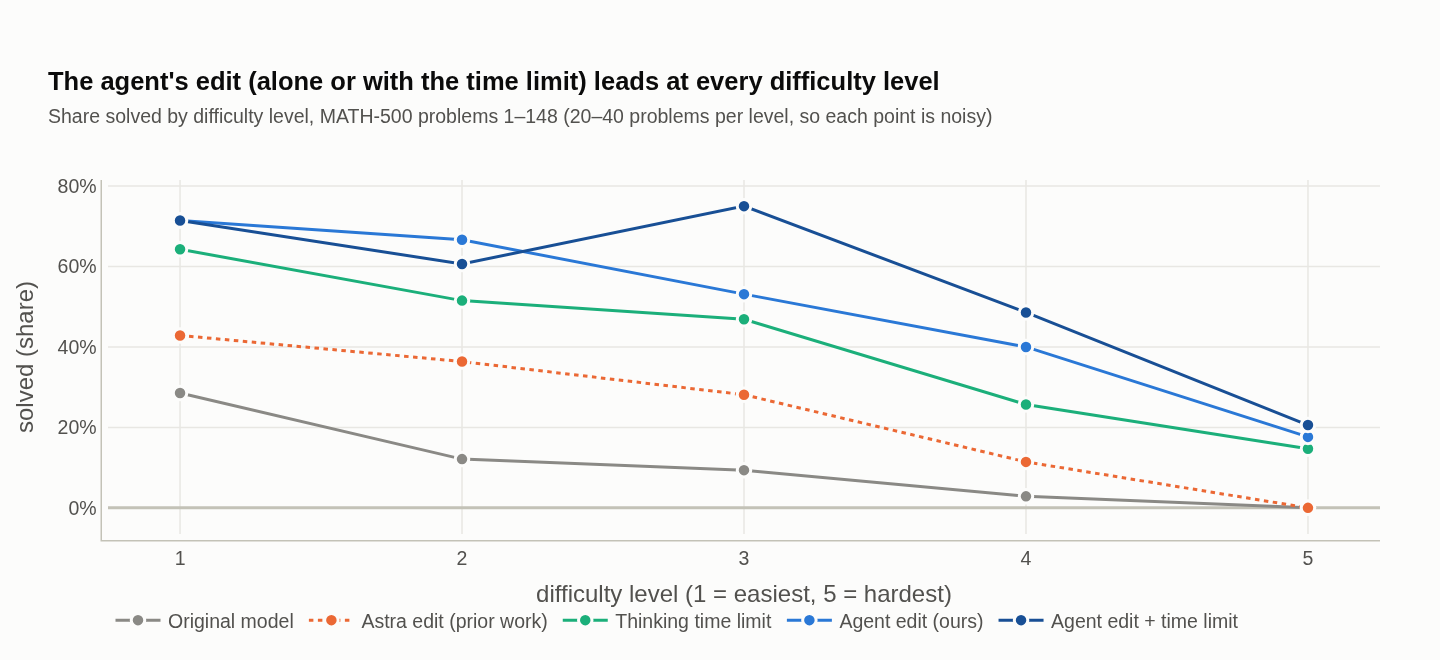

In [7]:
fig = go.Figure()
for arm in ["base", "astra", "bf4096", A1, A1 + "+bf4096"]:
    df = pd.DataFrame(rows("math148", arm))
    g = df.groupby("level").agg(k=("correct", "sum"), n=("correct", "size")).reset_index()
    g["p"] = g.k / g.n
    fig.add_scatter(x=g.level, y=g.p, mode="lines+markers", name=label(arm),
                    line=dict(color=color(arm), width=2, dash="dot" if arm == "astra" else "solid"),
                    marker=dict(size=9, color=color(arm), line=dict(color=SURFACE, width=2)),
                    customdata=g[["k", "n"]].values,
                    hovertemplate=f"<b>{label(arm)}</b><br>level %{{x}}: solved %{{customdata[0]}} of %{{customdata[1]}} (%{{y:.0%}})<extra></extra>")
style(fig, 440, "The agent's edit (alone or with the time limit) leads at every difficulty level",
      "Share solved by difficulty level, MATH-500 problems 1–148 (20–40 problems per level, so each point is noisy)")
fig.update_xaxes(title="difficulty level (1 = easiest, 5 = hardest)", dtick=1)
fig.update_yaxes(title="solved (share)", tickformat=".0%")
show(fig)

> **In practice:** harder problems need longer reasoning, which gives a looping model more chances to get stuck.
> A thinking time limit helps, but it also cuts off reasoning that was actually going somewhere. The edit removes
> the loop itself, so long reasoning can continue.

## 6. The trap: cheap scores lie

Running the model on real problems is slow: 16 problems take about 10 minutes. So we first gave the agents a fast
"quick score" that measures how much the model *wants* to repeat itself, without letting it actually write answers.
This chart checks whether that quick score predicts real performance.

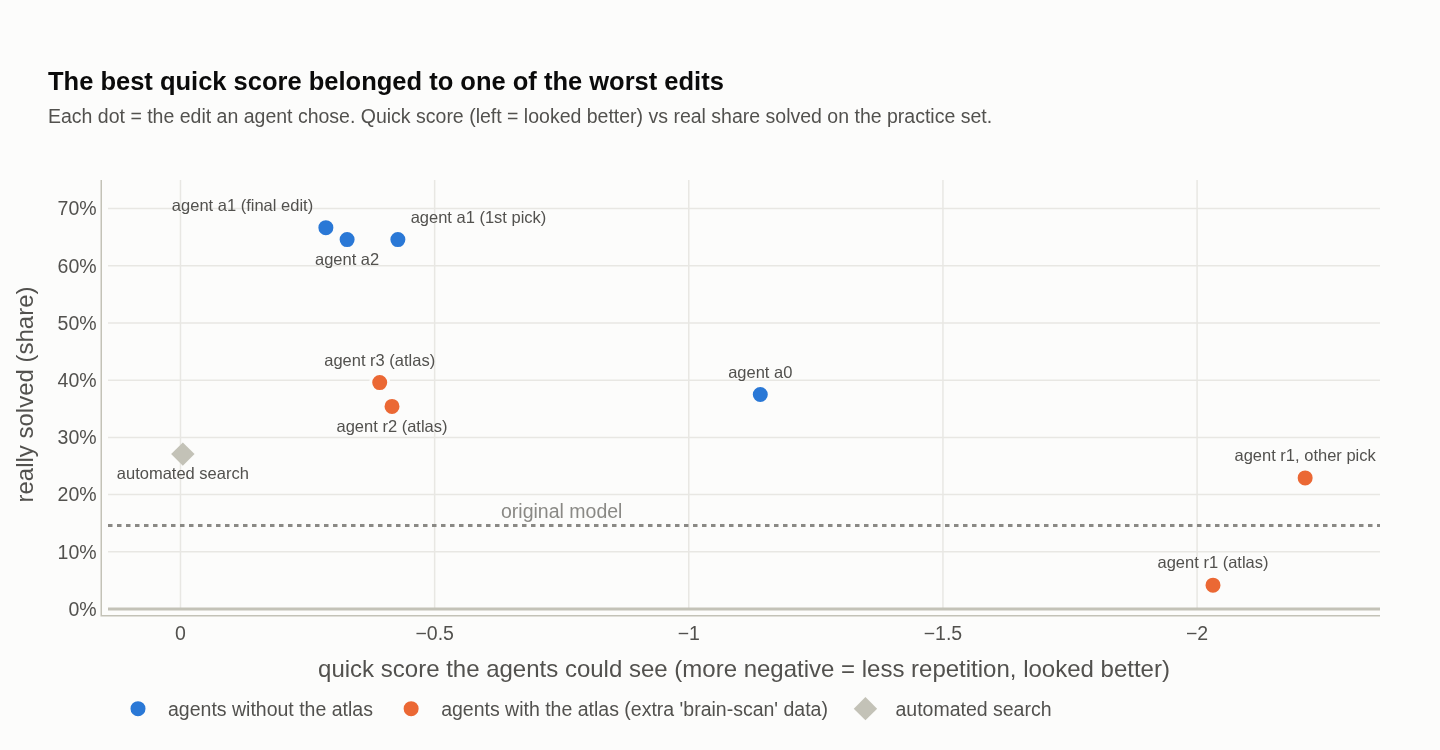

In [8]:
def ledger(run, kind="ledger"):
    p = DATA / "m2a" / "runs" / run / f"{kind}.jsonl"
    return [json.loads(l) for l in open(p)] if p.exists() else []

PICKS = [("m2a_a0", "a0", "agent a0"), ("m2a_r1", "r1", "agent r1 (atlas)"), ("m2a_r1_192156_139", "r1", "agent r1, other pick"),
         ("m2a_a1", "a1", "agent a1 (1st pick)"), (A1, "a1", "agent a1 (final edit)"), ("m2a_r2", "r2", "agent r2 (atlas)"),
         ("m2a_a2", "a2", "agent a2"), ("m2a_r3", "r3", "agent r3 (atlas)"), ("m2a_naive", "naive", "automated search")]
pts = []
for arm, run, name in PICKS:
    final = json.load(open(DATA / "m2a" / "runs" / run / "final.json"))
    cid = {"m2a_r1_192156_139": "192156_139", A1: "062959_102"}.get(arm, final["ranked"][0])
    br = {r["id"]: r["branch_rep"] for r in ledger(run)}.get(cid)
    if br is None: continue
    s = gen["dev48"][arm]["summary"]
    pts.append((name, br, s["acc"], s["cut"], run in ("r1", "r2", "r3")))
fig = go.Figure()
for atlas, col, nm in [(False, BLUE, "agents without the atlas"), (True, ORANGE, "agents with the atlas (extra 'brain-scan' data)")]:
    P = [p for p in pts if p[4] == atlas and p[0] != "automated search"]
    POS = {"agent a1 (final edit)": "top left", "agent a2": "bottom center", "agent a1 (1st pick)": "top right",
           "agent r3 (atlas)": "top center", "agent r2 (atlas)": "bottom center"}
    fig.add_scatter(x=[p[1] for p in P], y=[p[2] for p in P], mode="markers+text", name=nm, text=[p[0] for p in P],
                    textposition=[POS.get(p[0], "top center") for p in P], textfont=dict(color=INK2, size=11),
                    marker=dict(size=12, color=col, line=dict(color=SURFACE, width=2)),
                    customdata=[[p[0], p[3]] for p in P],
                    hovertemplate="<b>%{customdata[0]}</b><br>quick score: %{x:.2f} (more negative = looked better)<br>real result: solved %{y:.0%}, ran out of space %{customdata[1]:.0%}<extra></extra>")
P = [p for p in pts if p[0] == "automated search"]
fig.add_scatter(x=[p[1] for p in P], y=[p[2] for p in P], mode="markers+text", name="automated search", text=["automated search"],
                textposition="bottom center", textfont=dict(color=INK2, size=11), marker=dict(size=12, color=LIGHTGRAY, symbol="diamond"),
                hovertemplate="<b>automated search</b><br>quick score: %{x:.2f}<br>real result: solved %{y:.0%}<extra></extra>")
fig.add_hline(y=gen["dev48"]["base"]["summary"]["acc"], line_dash="dot", line_color=GRAY)
fig.add_annotation(x=-0.75, y=gen["dev48"]["base"]["summary"]["acc"], text="original model", showarrow=False, xanchor="center", yshift=10, font=dict(color=GRAY))
style(fig, 500, "The best quick score belonged to one of the worst edits",
      "Each dot = the edit an agent chose. Quick score (left = looked better) vs real share solved on the practice set.")
fig.update_xaxes(title="quick score the agents could see (more negative = less repetition, looked better)", autorange="reversed", zeroline=False)
fig.update_yaxes(title="really solved (share)", tickformat=".0%", range=[0, 0.75])
show(fig)

> **In practice:** agent r1 drove the quick score far lower than anyone else, and its edit solved **4%** of problems,
> worse than doing nothing. A strong optimizer finds whatever gap exists between the score and the real goal. The same
> thing happened with every cheap shortcut we tried. The fix was to let the agents run a few **real test runs**
> (6 runs of 16 problems each). The two strong edits, a1 and a2, both came from that protocol.

## 7. Surprise: more information made the agents worse

Some agents also got an **atlas**: a detailed scan of the model's internal activity while looping, which looks like
exactly what you would want for diagnosing the problem. We ran pairs of agents with identical instructions, one with
the atlas and one without.

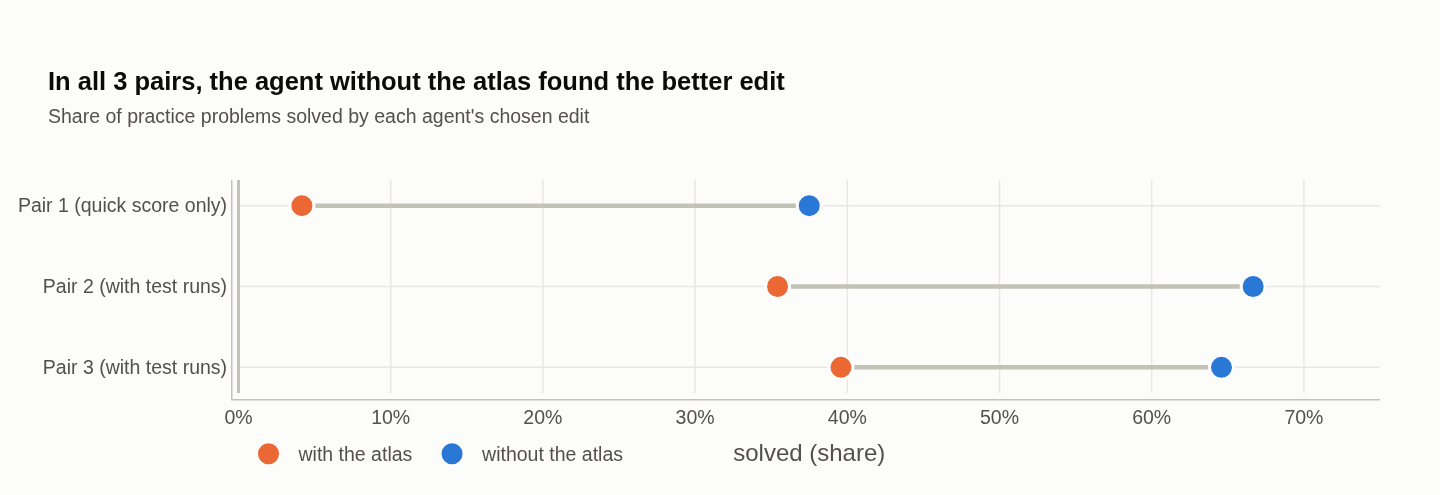

In [9]:
PAIRS = [("Pair 1 (quick score only)", "m2a_a0", "m2a_r1"), ("Pair 2 (with test runs)", A1, "m2a_r2"), ("Pair 3 (with test runs)", "m2a_a2", "m2a_r3")]
fig = go.Figure()
for name, no, yes in PAIRS:
    (kn, n), (ky, _) = acc("dev48", no), acc("dev48", yes)
    fig.add_scatter(x=[ky / n, kn / n], y=[name, name], mode="lines", line=dict(color=LIGHTGRAY, width=3), showlegend=False, hoverinfo="skip")
for i, (lab, idx, col) in enumerate([("with the atlas", 2, ORANGE), ("without the atlas", 1, BLUE)]):
    xs, cd = [], []
    for name, no, yes in PAIRS:
        arm = (name, no, yes)[idx]; k, n = acc("dev48", arm); xs.append(k / n); cd.append([k, n, lab])
    fig.add_scatter(x=xs, y=[p[0] for p in PAIRS], mode="markers", name=lab, marker=dict(size=16, color=col, line=dict(color=SURFACE, width=2)),
                    customdata=cd, hovertemplate="<b>%{y}, agent %{customdata[2]}</b><br>its edit solved %{customdata[0]} of %{customdata[1]} practice problems (%{x:.0%})<extra></extra>")
style(fig, 330, "In all 3 pairs, the agent without the atlas found the better edit",
      "Share of practice problems solved by each agent's chosen edit")
fig.update_xaxes(title="solved (share)", tickformat=".0%", range=[0, 0.75])
fig.update_yaxes(autorange="reversed")
show(fig)

> **In practice:** the atlas led agents toward intricate internal mechanisms that looked convincing in the data but
> didn't fix the behavior. The agents without it went for the simple, direct lever: the urge to say "Wait" and the
> signal to stop thinking. With only 3 pairs this is suggestive rather than proven, but the direction was the same
> every time.

## 8. What the agents actually did in their ~2 hours

Each bar is one real test run that a searcher asked for: the edited model on 16 practice problems. Every searcher had
6 test runs. The automated search had exactly the same budget and the same feedback.

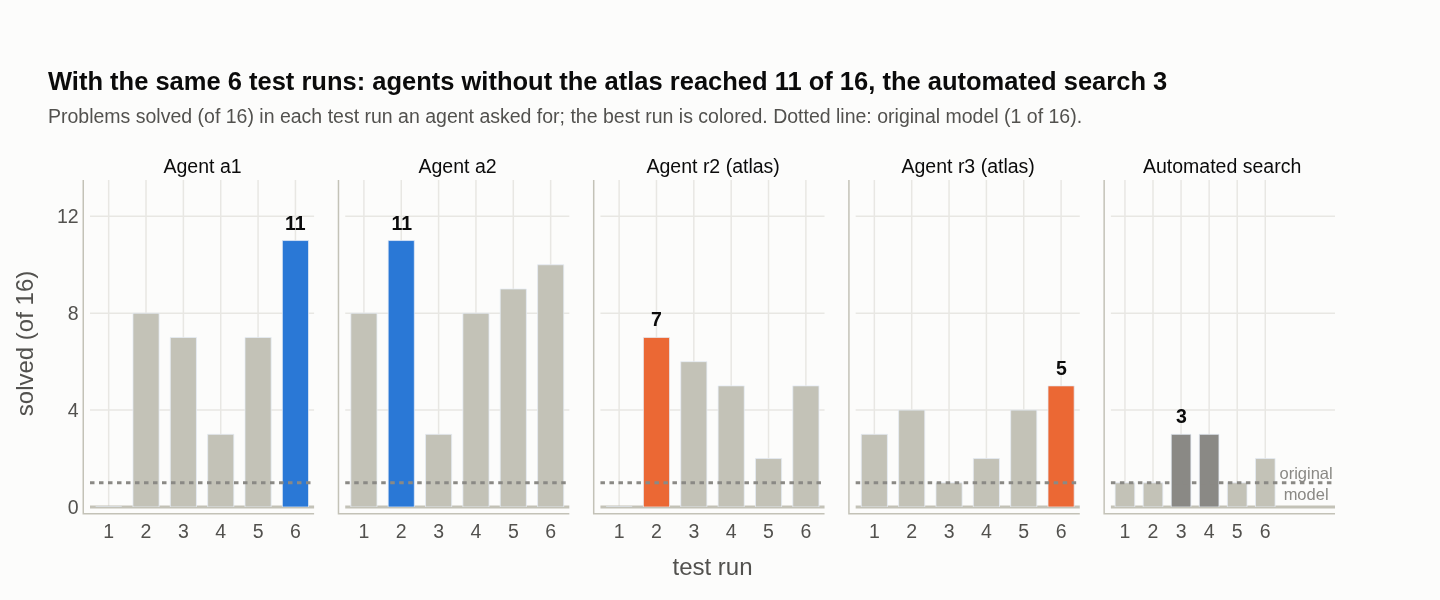

In [10]:
RUNS = [("a1", "Agent a1", BLUE), ("a2", "Agent a2", BLUE), ("r2", "Agent r2 (atlas)", ORANGE),
        ("r3", "Agent r3 (atlas)", ORANGE), ("naive", "Automated search", GRAY)]
fig = make_subplots(rows=1, cols=5, shared_yaxes=True, horizontal_spacing=0.025, subplot_titles=[r[1] for r in RUNS])
for c, (run, name, col) in enumerate(RUNS, start=1):
    probes, gens = ledger(run), ledger(run, "gen_ledger")
    t0 = datetime.fromisoformat(probes[0]["ts"]) if probes else datetime.fromisoformat(gens[0]["ts"])
    k = [round(g["acc"] * 16) for g in gens]
    best = max(k)
    fig.add_bar(x=list(range(1, len(k) + 1)), y=k, marker_color=[col if v == best else LIGHTGRAY for v in k], showlegend=False,
                customdata=[[name, round(g["cut"] * 16), (datetime.fromisoformat(g["ts"]) - t0).total_seconds() / 60] for g in gens],
                hovertemplate="<b>%{customdata[0]}</b>, test run %{x} of 6 (minute %{customdata[2]:.0f})<br>solved %{y} of 16 · ran out of space on %{customdata[1]} of 16<extra></extra>",
                row=1, col=c)
    fig.add_annotation(x=k.index(best) + 1, y=best, text=f"<b>{best}</b>", showarrow=False, yshift=12, font=dict(color=INK, size=13), row=1, col=c)
    fig.add_hline(y=1, line_dash="dot", line_color=GRAY, row=1, col=c)
    fig.update_xaxes(tickvals=list(range(1, 7)), title="test run" if c == 3 else None, row=1, col=c)
fig.add_annotation(x=6.4, y=1, xref="x5", yref="y", text="original<br>model", showarrow=False, xanchor="left", font=dict(color=GRAY, size=11))
style(fig, 400, "With the same 6 test runs: agents without the atlas reached 11 of 16, the automated search 3",
      "Problems solved (of 16) in each test run an agent asked for; the best run is colored. Dotted line: original model (1 of 16).")
fig.update_yaxes(range=[0, 13.5], dtick=4)
fig.update_yaxes(title="solved (of 16)", row=1, col=1)
fig.update_layout(bargap=0.3, margin=dict(r=70))
for a in fig.layout.annotations[:5]:
    a.font = dict(size=13, color=INK)
show(fig)

> **In practice:** with the same 6 test runs, what differs is *what each searcher chose to try*. It read its own failures: an edit that made the
> model say "wait wait wait" told it that the neurons fire the opposite way from what it had assumed. It then
> combined two weak fixes into one strong one. The automated search had the same tools and never found that
> combination.

## 9. Why didn't fine-tuning do better?

We trained the model on 175 examples of its own reasoning with the loops cut out. Left: the training
<abbr title="How surprised the model is by the training examples; lower means it reproduces them more closely">loss</abbr>.
Right: the check we used to pick which training round to keep.

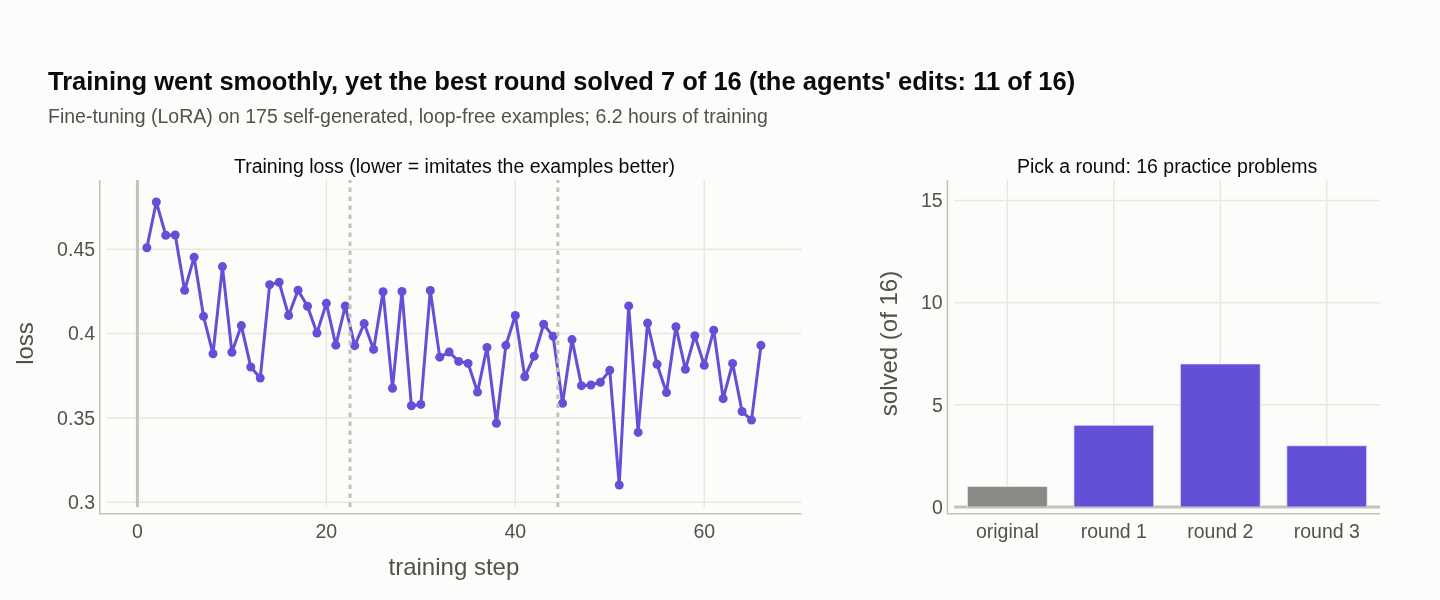

Of 600 attempts, only **57** finished cleanly on their own and **118** were usable after cutting out the loop. The remaining 425 could not be used.

In [11]:
log = [json.loads(l) for l in open(DATA / "ft" / "sft" / "log.jsonl")]
sel = load("gen_ftsel.json")["arms"]
fig = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38], horizontal_spacing=0.12,
                    subplot_titles=["Training loss (lower = imitates the examples better)", "Pick a round: 16 practice problems"])
fig.add_scatter(x=[r["step"] for r in log], y=[r["loss"] for r in log], mode="lines+markers", line=dict(color=VIOLET, width=2),
                marker=dict(size=6, color=VIOLET), showlegend=False, customdata=[[r["ep"], r["min"]] for r in log],
                hovertemplate="step %{x} (round %{customdata[0]}), after %{customdata[1]:.0f} minutes<br>loss %{y:.3f}<extra></extra>", row=1, col=1)
for x in (22.5, 44.5):
    fig.add_vline(x=x, line_dash="dot", line_color=LIGHTGRAY, row=1, col=1)
names = {"base": "original", "ft_sft_ep1": "round 1", "ft_sft_ep2": "round 2", "ft_sft_ep3": "round 3"}
for a, nm in names.items():
    s = sel[a]["summary"]
    fig.add_bar(x=[nm], y=[round(s["acc"] * 16)], marker_color=VIOLET if a != "base" else GRAY, showlegend=False,
                customdata=[[round(s["cut"] * 16)]], hovertemplate=f"<b>{nm}</b><br>solved %{{y}} of 16 · ran out of space on %{{customdata[0]}} of 16<extra></extra>", row=1, col=2)
style(fig, 400, "Training went smoothly, yet the best round solved 7 of 16 (the agents' edits: 11 of 16)",
      "Fine-tuning (LoRA) on 175 self-generated, loop-free examples; 6.2 hours of training")
fig.update_xaxes(title="training step", row=1, col=1); fig.update_yaxes(title="loss", row=1, col=1)
fig.update_yaxes(title="solved (of 16)", range=[0, 16], row=1, col=2)
for a in fig.layout.annotations[:2]:
    a.font = dict(size=13, color=INK)
show(fig)
st = load("ft/sft_stats.json")
display(Markdown(f"Of {st['n']} attempts, only **{st['natural']}** finished cleanly on their own and **{st['excised']}** were usable after "
                 f"cutting out the loop. The remaining {st['n'] - st['natural'] - st['excised']} could not be used."))

> **In practice:** the model learned to *imitate the examples*, so the loss went down. It still did not learn *when to
> stop*. Most training examples showed "reasoning that was cut short, then an answer", which teaches what to do after
> a cut, not how to avoid looping. Making the examples was also expensive: the looping model wasted most of its
> attempts. On the practice set, the chosen round solved 29% (14 of 48), against 67% for the agent's edit.

## 10. What it costs

Two different costs:
- the **one-time cost** of producing the fix;
- the **running cost**: how much text the model generates every time it answers. Longer answers mean slower
  responses and higher serving bills.

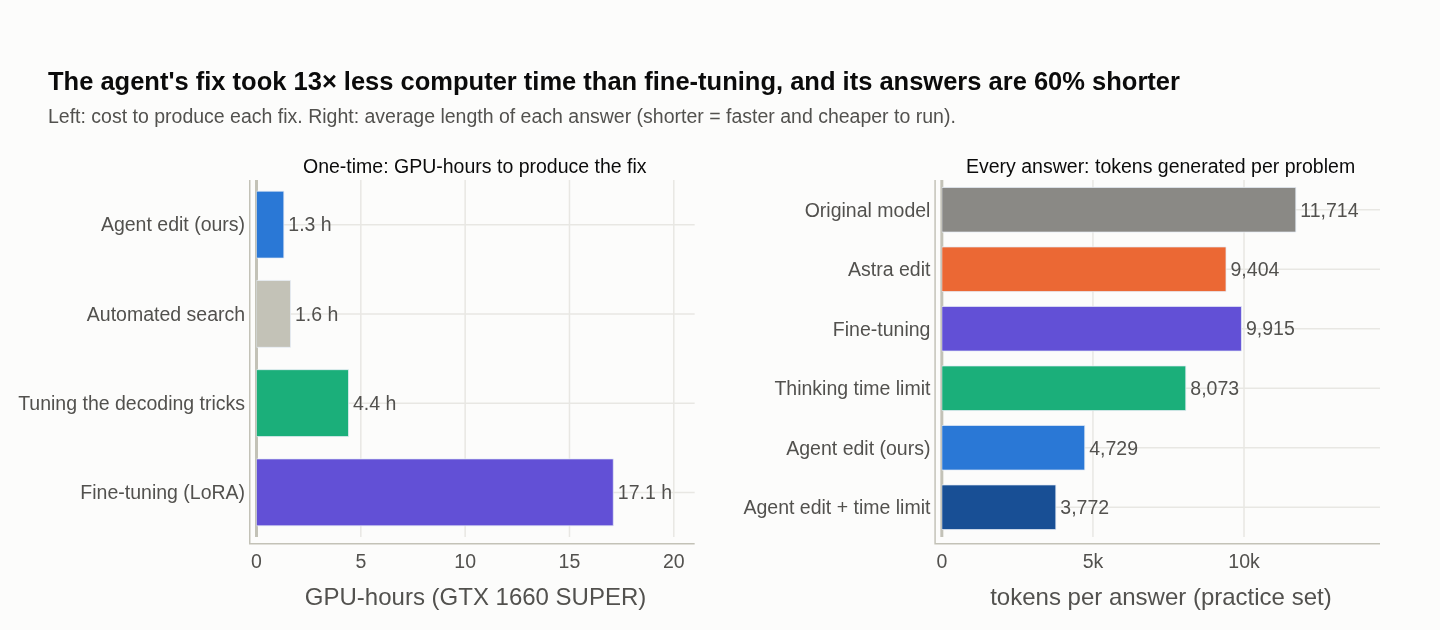

In [12]:
cost = load("cost.json")
items = [("Agent edit (ours)", cost["agents"]["a1"]["gpu_h"], BLUE, "1 agent run: 18 quick scores + 6 test runs, about 2 hours wall-clock.<br>Plus about $5–7 of AI-agent usage at API prices."),
         ("Automated search", cost["agents"]["naive"]["gpu_h"], LIGHTGRAY, "Same budget as the agent, no AI reasoning."),
         ("Tuning the decoding tricks", cost["decoding_tuning_gpu_h"], AQUA, "Trying 5 settings of the word ban and the time limit on the practice set."),
         ("Fine-tuning (LoRA)", cost["e4_gpu_h"]["total"], VIOLET, "Generating 600 example answers (10.2 h) + training (6.3 h) + picking a round (0.5 h).")]
serve = cost["dev48_mean_tokens"]
sv = [("Original model", serve["base"], GRAY), ("Astra edit", serve["astra"], ORANGE), ("Fine-tuning", serve["ft_sft_ep2"], VIOLET),
      ("Thinking time limit", serve["bf4096"], AQUA), ("Agent edit (ours)", serve[A1], BLUE), ("Agent edit + time limit", serve[A1 + "+bf4096"], NAVY)]
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.22,
                    subplot_titles=["One-time: GPU-hours to produce the fix", "Every answer: tokens generated per problem"])
for nm, h, col, d in items:
    fig.add_bar(y=[nm], x=[h], orientation="h", marker_color=col, showlegend=False, text=[f"{h:.1f} h"], textposition="outside",
                customdata=[[h * 0.2, h * 0.2 * 60, d]],
                hovertemplate="<b>%{y}</b>: %{x:.1f} GPU-hours<br>≈ %{customdata[0]:.2f} kWh, like running a microwave for %{customdata[1]:.0f} minutes<br><br>%{customdata[2]}<extra></extra>",
                row=1, col=1)
base_t = serve["base"]
for nm, t, col in sv:
    fig.add_bar(y=[nm], x=[t], orientation="h", marker_color=col, showlegend=False, text=[f"{t:,.0f}"], textposition="outside",
                customdata=[[t * 0.75, t * 0.75 / 500, (1 - t / base_t) * 100]],
                hovertemplate="<b>%{y}</b>: %{x:,.0f} tokens per answer on average<br>≈ %{customdata[0]:,.0f} words, about %{customdata[1]:.0f} pages<br>%{customdata[2]:.0f}% less than the original model<extra></extra>",
                row=1, col=2)
fig.update_yaxes(categoryorder="array", categoryarray=[i[0] for i in items][::-1], row=1, col=1)
fig.update_yaxes(categoryorder="array", categoryarray=[s[0] for s in sv][::-1], row=1, col=2)
fig.update_xaxes(range=[0, 21], title="GPU-hours (GTX 1660 SUPER)", row=1, col=1)
fig.update_xaxes(range=[0, 14500], title="tokens per answer (practice set)", row=1, col=2)
style(fig, 420, "The agent's fix took 13× less computer time than fine-tuning, and its answers are 60% shorter",
      "Left: cost to produce each fix. Right: average length of each answer (shorter = faster and cheaper to run).")
for a in fig.layout.annotations[:2]:
    a.font = dict(size=13, color=INK)
show(fig)

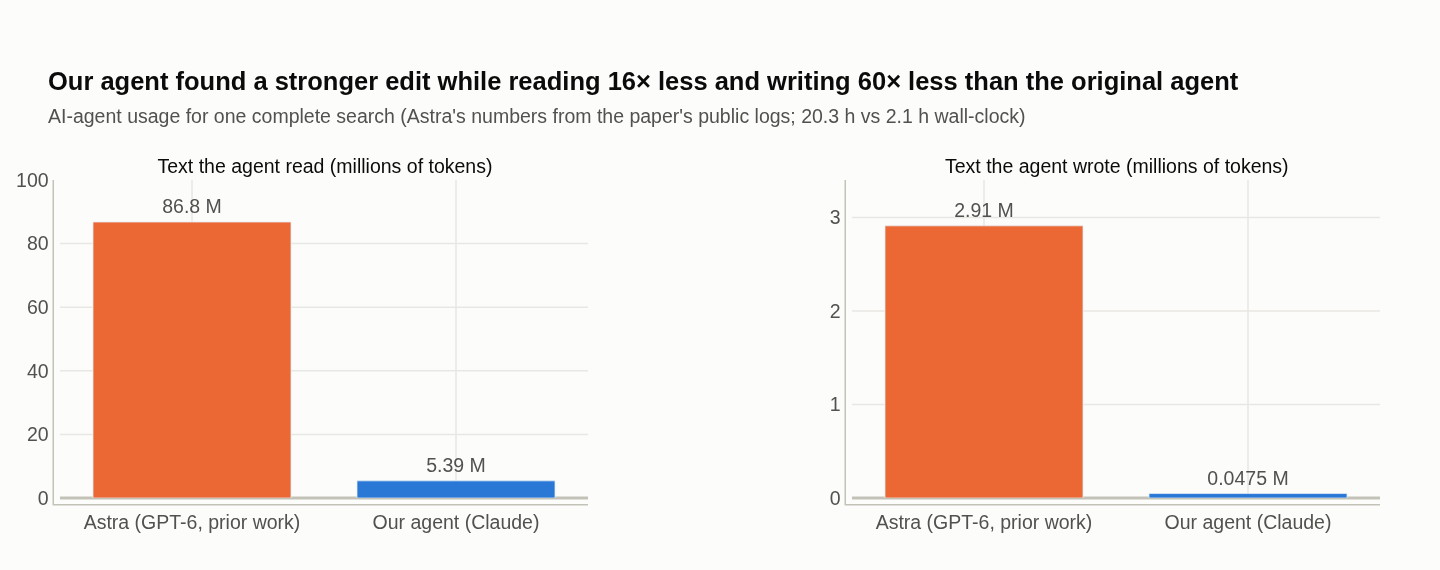

In [13]:
astra = cost["astra"]["p50c"]; a1 = cost["agents"]["a1"]
ctx_a1 = a1["input_tokens"] + a1["cache_read_input_tokens"] + a1["cache_creation_input_tokens"]
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.2,
                    subplot_titles=["Text the agent read (millions of tokens)", "Text the agent wrote (millions of tokens)"])
for j, (vals, unit) in enumerate([((astra["input_tokens"], ctx_a1), "read"), ((astra["output_tokens"], a1["output_tokens"]), "wrote")], start=1):
    for nm, v, col in [("Astra (GPT-6, prior work)", vals[0], ORANGE), ("Our agent (Claude)", vals[1], BLUE)]:
        fig.add_bar(x=[nm], y=[v / 1e6], marker_color=col, showlegend=False, text=[f"{v/1e6:.3g} M"], textposition="outside",
                    customdata=[[v * 0.75 / 500]],
                    hovertemplate=f"<b>%{{x}}</b> {unit} %{{y:.2f}} million tokens<br>≈ %{{customdata[0]:,.0f}} pages of text<extra></extra>", row=1, col=j)
fig.update_yaxes(range=[0, 100], row=1, col=1); fig.update_yaxes(range=[0, 3.4], row=1, col=2)
style(fig, 380, "Our agent found a stronger edit while reading 16× less and writing 60× less than the original agent",
      "AI-agent usage for one complete search (Astra's numbers from the paper's public logs; 20.3 h vs 2.1 h wall-clock)")
for a in fig.layout.annotations[:2]:
    a.font = dict(size=13, color=INK)
show(fig)

> **In practice:**
> - **One-time cost.** One agent run is about two hours on a gaming GPU plus a few dollars of AI-agent usage. That is
>   less electricity than running a microwave for 20 minutes. Fine-tuning needed a whole night and morning of GPU
>   time for a worse result.
> - **Running cost.** The edited model gives its answers in **less than half the text**. That saving repeats on every
>   question it ever answers, which for a deployed model matters more than the one-time cost.
> - **Caveats.** On a much cheaper rented GPU, fine-tuning could cost a few dollars less than the agent's usage, but it
>   delivers less than half the improvement. The comparison with Astra is not a controlled experiment: different
>   agents and different tooling. Details are in `docs/cost.md`.

## 11. Did the surgery break anything else?

A good fix should not damage unrelated skills. We checked the edited models on tasks where looping is not the issue:
math with thinking switched **off**, and choosing the right software tool for a request (tool calling).

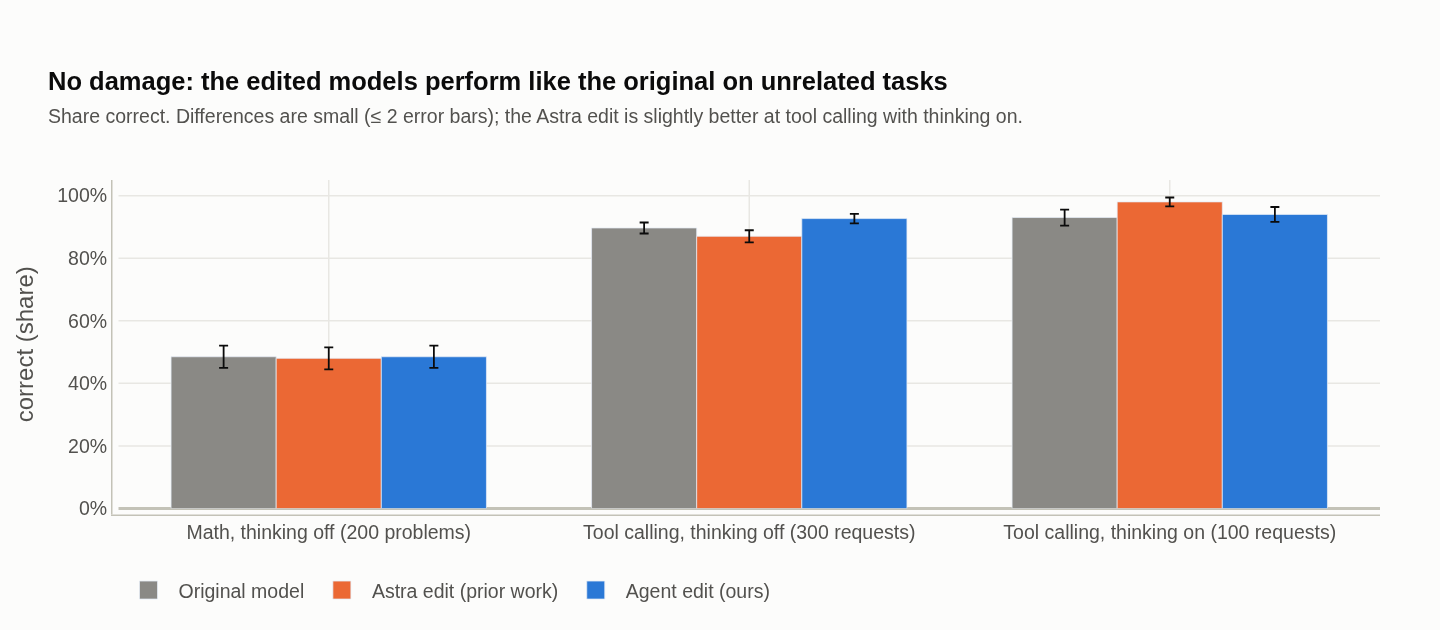

In [14]:
side = {"Math, thinking off (200 problems)": load("gen_nothink_n200.json")["arms"],
        "Tool calling, thinking off (300 requests)": load("tool_nothink_dev300.json")["arms"],
        "Tool calling, thinking on (100 requests)": load("tool_think_dev100.json")["arms"]}
fig = go.Figure()
for arm in ["base", "astra", A1]:
    xs, ys, errs, cd = [], [], [], []
    for task, arms in side.items():
        s, n = arms[arm]["summary"], len(arms[arm]["rows"])
        p = s.get("acc", s.get("exact"))
        xs.append(task); ys.append(p); errs.append(se(p, n)); cd.append([round(p * n), n])
    fig.add_bar(x=xs, y=ys, name=label(arm), marker_color=color(arm),
                error_y=dict(type="data", array=errs, color=INK, thickness=1.2, width=3), customdata=cd,
                hovertemplate=f"<b>{label(arm)}</b><br>%{{x}}<br>%{{customdata[0]}} of %{{customdata[1]}} right (%{{y:.0%}})<extra></extra>")
style(fig, 420, "No damage: the edited models perform like the original on unrelated tasks",
      "Share correct. Differences are small (≤ 2 error bars); the Astra edit is slightly better at tool calling with thinking on.")
fig.update_layout(barmode="group")
fig.update_yaxes(title="correct (share)", tickformat=".0%", range=[0, 1.05])
show(fig)

> **In practice:** the edit is **surgical**. It changes behavior only where the loops happen, during thinking, and
> leaves other skills alone. That is what you would expect from four tiny changes aimed at one habit.

## What we learned

1. **An AI agent can repair a specific bad habit in another AI model by editing its weights directly**, with no
   retraining: four tiny changes, about 2 hours, one gaming GPU.
2. **The fix is strong and real.** It takes the model from 15% to 67% on practice problems and from 8% to 47% on
   harder, unseen competition math. It almost never loses a problem that another method solves.
3. **It beat fine-tuning**: 2.3× the accuracy at 1/13 of the computer time, and its answers are 60% shorter.
4. **It is not just a trick of the decoding settings.** It outperforms banning the word "Wait" and capping the
   thinking time, and it combines with the time limit for the best result of all.
5. **The agent's reasoning matters.** An automated search with the same tools and feedback failed.
6. **Real test runs are essential.** Every cheap shortcut score was eventually gamed.
7. **More data isn't always better.** Agents given a detailed brain scan found worse fixes, in 3 of 3 pairs.

## What we can't claim yet

- **Small samples.** Most results rest on 32–148 problems. The harder-math comparison is the most solid; a larger
  locked test is planned.
- **One model, one defect.** "Wait" is an easy word to target. The next test is a defect with no obvious keyword,
  and a second model.
- **One fine-tuning recipe.** Larger datasets or reinforcement learning might do better, at a higher cost.
- **Honor system.** The agents were told what not to read, and we audited every action they took. No violations were
  found, but the rules were not technically enforced.

*Primary lab notebook: `docs/CADERNO.md` (Portuguese). Technical write-up: `docs/research-notes.md`. Costs:
`docs/cost.md`.*